In [1]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

model_results = pd.read_csv(
    REPORT_DIR / "final_model_comparison.csv"
)

targeting_results = pd.read_csv(
    REPORT_DIR / "risk_targeting_results.csv"
)

segment_results = pd.read_csv(
    REPORT_DIR / "retention_segment_comparison.csv"
)

power_results = pd.read_csv(
    REPORT_DIR / "retention_power_analysis.csv"
)

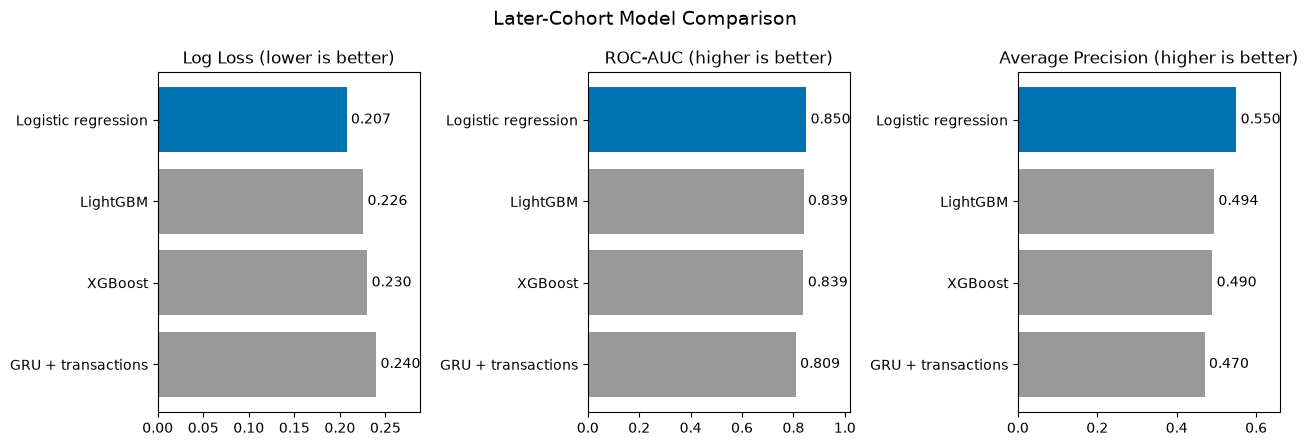

In [2]:
plot_data = model_results.sort_values("log_loss").reset_index(drop=True)

labels = plot_data["model"].replace({
    "Logistic regression": "Logistic regression",
    "GRU + transaction inputs": "GRU + transactions",
})

colors = [
    "#0072B2" if name == "Logistic regression" else "#999999"
    for name in plot_data["model"]
]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))

for ax, metric, title in [
    (axes[0], "log_loss", "Log Loss (lower is better)"),
    (axes[1], "roc_auc", "ROC-AUC (higher is better)"),
    (axes[2], "average_precision", "Average Precision (higher is better)"),
]:
    bars = ax.barh(labels, plot_data[metric], color=colors)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlim(0, plot_data[metric].max() * 1.2)

    for bar, value in zip(bars, plot_data[metric]):
        ax.text(
            value + plot_data[metric].max() * 0.02,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center",
        )

fig.suptitle("Later-Cohort Model Comparison", fontsize=14)
fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "final_model_comparison.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

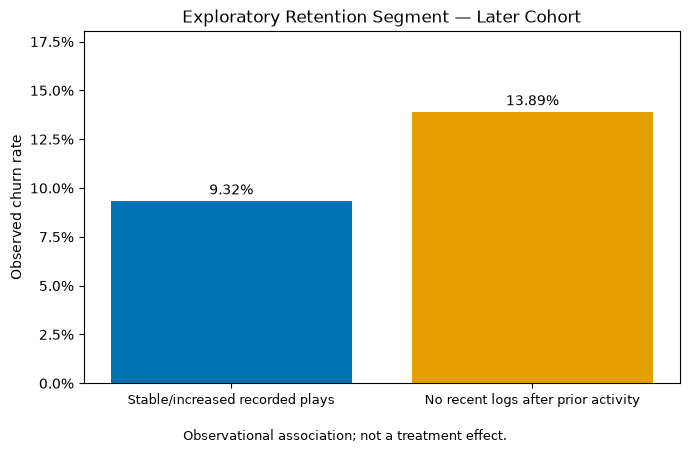

In [3]:
later_segment = segment_results.loc[
    segment_results["cohort"] == "later_evaluation"
].iloc[0]

rates = [
    later_segment["reference_churn_rate"],
    later_segment["target_churn_rate"],
]

fig, ax = plt.subplots(figsize=(7, 4.5))

bars = ax.bar(
    ["Stable/increased recorded plays", "No recent logs after prior activity"],
    rates,
    color=["#0072B2", "#E69F00"],
)

for bar, rate in zip(bars, rates):
    ax.annotate(
        f"{rate:.2%}",
        xy=(bar.get_x() + bar.get_width() / 2, rate),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
    )

ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, max(rates) * 1.3)
ax.set_ylabel("Observed churn rate")
ax.set_title("Exploratory Retention Segment — Later Cohort")
ax.tick_params(axis="x", labelsize=9)

fig.text(
    0.5,
    0.01,
    "Observational association; not a treatment effect.",
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

fig.savefig(
    FIGURE_DIR / "retention_target_segment.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

In [4]:
preview_replacements = {
    "01_data_audit.ipynb": [
        (
            r"train\.head\(\)",
            'train.dtypes.rename("dtype").to_frame()',
        ),
        (
            r"(?m)^members_preview[ \t]*$",
            'members_preview.dtypes.rename("preview_dtype").to_frame()',
        ),
    ],
    "02_transaction_audit.ipynb": [
        (
            r"display\(preview\)",
            'display(preview.dtypes.rename("preview_dtype").to_frame())',
        ),
    ],
    "09_user_logs_audit.ipynb": [
        (
            r"display\(logs_preview\)",
            "# Raw user-level preview output is omitted.",
        ),
    ],
}

for filename, replacements in preview_replacements.items():
    path = PROJECT_ROOT / "notebooks" / filename
    notebook = json.loads(path.read_text(encoding="utf-8"))

    changed_cells = 0

    for cell in notebook["cells"]:
        if cell["cell_type"] != "code":
            continue

        original = "".join(cell.get("source", []))
        updated = original

        for pattern, replacement in replacements:
            updated = re.sub(pattern, replacement, updated)

        if updated != original:
            cell["source"] = updated.splitlines(keepends=True)
            cell["outputs"] = []
            cell["execution_count"] = None
            changed_cells += 1

    if changed_cells:
        path.write_text(
            json.dumps(notebook, indent=1, ensure_ascii=False) + "\n",
            encoding="utf-8",
        )

    print(f"{filename}: updated {changed_cells} preview cells")

01_data_audit.ipynb: updated 2 preview cells
02_transaction_audit.ipynb: updated 1 preview cells
09_user_logs_audit.ipynb: updated 1 preview cells
